# UK Online Retailer: Sales and Customer Analysis

**Question:** Where does this business's revenue come from, how seasonal is it, and which customers keep coming back?

**Data:** the *Online Retail* dataset (UCI Machine Learning Repository, Chen, Sain & Guo, 2012): every transaction from a UK-based online gift retailer between 1 December 2010 and 9 December 2011. Many of its customers are wholesalers. 541,909 invoice lines, 8 columns.

**Tools:** Python (pandas, matplotlib), SQL (SQLite).

**What this notebook does**
1. Profiles the raw data and logs every cleaning step with row counts
2. Answers core business questions in SQL (`queries.sql`)
3. Looks at seasonality, trading hours, export markets and product concentration
4. Segments customers with RFM (recency, frequency, monetary value)
5. Measures repeat purchasing with monthly cohort retention

In [1]:
import json, os, re, sqlite3, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 12,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
os.makedirs("images", exist_ok=True); os.makedirs("results", exist_ok=True); os.makedirs("data", exist_ok=True)

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/"
            "master/data/retail-data/all/online-retail-dataset.csv")
DATA_PATH = "data/online_retail.csv"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw = pd.read_csv(DATA_PATH, dtype={"InvoiceNo": str, "StockCode": str, "CustomerID": str})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 1. Data quality profile

In [3]:
profile = pd.DataFrame({
    "check": [
        "Rows", "Missing CustomerID", "Missing Description", "Exact duplicate rows",
        "Cancellation lines (InvoiceNo starts with C)", "Quantity <= 0", "UnitPrice <= 0",
        "Non-product stock codes (postage, fees, manual adjustments)",
    ],
    "rows": [
        len(raw), raw["CustomerID"].isna().sum(), raw["Description"].isna().sum(), raw.duplicated().sum(),
        raw["InvoiceNo"].str.startswith("C").sum(), (raw["Quantity"] <= 0).sum(), (raw["UnitPrice"] <= 0).sum(),
        raw["StockCode"].str.upper().isin(["POST","DOT","M","C2","D","S","BANK CHARGES","AMAZONFEE","CRUK","B","PADS"]).sum()
        + raw["StockCode"].str.startswith("gift_").sum(),
    ],
})
profile["pct_of_rows"] = (100 * profile["rows"] / len(raw)).round(2)
profile

,check,rows,pct_of_rows
0,Rows,541909,100.00
1,Missing CustomerID,135080,24.93
2,Missing Description,1454,0.27
3,Exact duplicate rows,5268,0.97
4,Cancellation lines (InvoiceNo starts with C),9288,1.71
5,Quantity <= 0,10624,1.96
6,UnitPrice <= 0,2517,0.46
7,"Non-product stock codes (postage, fees, manual...",2950,0.54


A quarter of lines have no `CustomerID`. These are guest checkouts: they count towards revenue but cannot be used for customer-level analysis (RFM, cohorts), so the notebook keeps them for sales figures and drops them only for customer work.

In [4]:
NON_PRODUCT = {"POST","DOT","M","C2","D","S","BANK CHARGES","AMAZONFEE","CRUK","B","PADS"}
log = [("Raw data", len(raw))]

df = raw.drop_duplicates()
log.append(("Remove exact duplicate rows", len(df)))

cancellations = df[df["InvoiceNo"].str.startswith("C")].copy()
df = df[~df["InvoiceNo"].str.startswith("C")]
log.append(("Set aside cancellations", len(df)))

is_non_product = df["StockCode"].str.upper().isin(NON_PRODUCT) | df["StockCode"].str.startswith("gift_")
df = df[~is_non_product]
log.append(("Remove postage, fees and manual adjustments", len(df)))

df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
log.append(("Remove zero/negative quantity or price", len(df)))

df = df.assign(
    Revenue=df["Quantity"] * df["UnitPrice"],
    Month=df["InvoiceDate"].dt.to_period("M"),
)
cleaning_log = pd.DataFrame(log, columns=["step", "rows_remaining"])
cleaning_log["rows_removed"] = (-cleaning_log["rows_remaining"].diff()).fillna(0).astype(int)
cleaning_log

,step,rows_remaining,rows_removed
0,Raw data,541909,0
1,Remove exact duplicate rows,536641,5268
2,Set aside cancellations,527390,9251
3,"Remove postage, fees and manual adjustments",525029,2361
4,Remove zero/negative quantity or price,522537,2492


The data ends on **9 December 2011**, so December 2011 is a partial month. Monthly charts below use the twelve full months, December 2010 to November 2011, and say so.

In [5]:
FULL = df[df["InvoiceDate"] < "2011-12-01"]
cust = FULL.dropna(subset=["CustomerID"])
orders = FULL.groupby("InvoiceNo")["Revenue"].sum()
gross_with_cancels = FULL["Revenue"].sum()
cancel_value = -(cancellations.loc[cancellations["InvoiceDate"] < "2011-12-01", "Quantity"]
                 * cancellations.loc[cancellations["InvoiceDate"] < "2011-12-01", "UnitPrice"]).sum()

kpis = {
    "period": "Dec 2010 to Nov 2011 (12 full months)",
    "revenue": round(FULL["Revenue"].sum(), 2),
    "orders": int(FULL["InvoiceNo"].nunique()),
    "customers": int(cust["CustomerID"].nunique()),
    "countries": int(FULL["Country"].nunique()),
    "products": int(FULL["StockCode"].nunique()),
    "avg_order_value": round(orders.mean(), 2),
    "median_order_value": round(orders.median(), 2),
    "uk_revenue_share_pct": round(100 * FULL.loc[FULL["Country"] == "United Kingdom", "Revenue"].sum() / FULL["Revenue"].sum(), 1),
    "guest_revenue_share_pct": round(100 * FULL.loc[FULL["CustomerID"].isna(), "Revenue"].sum() / FULL["Revenue"].sum(), 1),
    "cancelled_value_pct_of_sales": round(100 * cancel_value / gross_with_cancels, 1),
}
pd.Series(kpis)

period                          Dec 2010 to Nov 2011 (12 full months)
revenue                                                  9,632,728.40
orders                                                          18957
customers                                                        4293
countries                                                          38
products                                                         3904
avg_order_value                                                508.14
median_order_value                                             302.31
uk_revenue_share_pct                                            84.60
guest_revenue_share_pct                                         14.60
cancelled_value_pct_of_sales                                     7.20
dtype: object

## 2. Business questions in SQL

The cleaned sales lines for the twelve full months are loaded into an in-memory SQLite database and queried with the SQL in `queries.sql`.

In [6]:
con = sqlite3.connect(":memory:")
(FULL.rename(columns={"InvoiceNo": "invoice_no", "StockCode": "stock_code", "Description": "description",
                    "Quantity": "quantity", "InvoiceDate": "invoice_date", "UnitPrice": "unit_price",
                    "CustomerID": "customer_id", "Country": "country", "Revenue": "revenue"})
   .assign(month=lambda d: d["Month"].astype(str), invoice_date=lambda d: d["invoice_date"].astype(str))
   .drop(columns="Month")
   .to_sql("sales", con, index=False))

sql_text = open("queries.sql").read()
QUERIES = {m.group(1): m.group(2).strip() for m in re.finditer(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", sql_text, re.S)}
def q(name):
    return pd.read_sql(QUERIES[name], con)
list(QUERIES)

['monthly_revenue',
 'top_countries_outside_uk',
 'repeat_customer_rate',
 'average_order_value_by_customer_type']

In [7]:
q("monthly_revenue")

,month,revenue,orders,customers
0,2010-12,"775,638.36",1550,884
1,2011-01,"670,380.24",1081,739
2,2011-02,"507,799.87",1093,757
3,2011-03,"689,833.51",1440,973
4,2011-04,"515,377.99",1235,853
5,2011-05,"739,953.00",1668,1054
6,2011-06,"737,558.98",1525,990
7,2011-07,"688,219.34",1452,946
8,2011-08,"724,216.50",1339,933
9,2011-09,"1,028,320.38",1818,1259


In [8]:
q("top_countries_outside_uk")

,country,revenue,customers,orders
0,Netherlands,"272,161.32",9,90
1,EIRE,"263,709.97",3,272
2,Germany,"198,356.98",93,426
3,France,"177,954.08",86,365
4,Australia,"138,103.81",9,56
5,Spain,"55,418.35",29,86
6,Switzerland,"53,065.60",21,50
7,Japan,"37,416.37",8,19
8,Sweden,"36,590.83",8,33
9,Belgium,"35,638.61",25,94


In [9]:
q("repeat_customer_rate")

,customers,repeat_customers,repeat_rate_pct
0,4293,2742,63.90


In [10]:
q("average_order_value_by_customer_type")

,customer_type,orders,avg_order_value
0,Guest,1331,"1,057.65"
1,Identified,17626,466.64


## 3. Seasonality

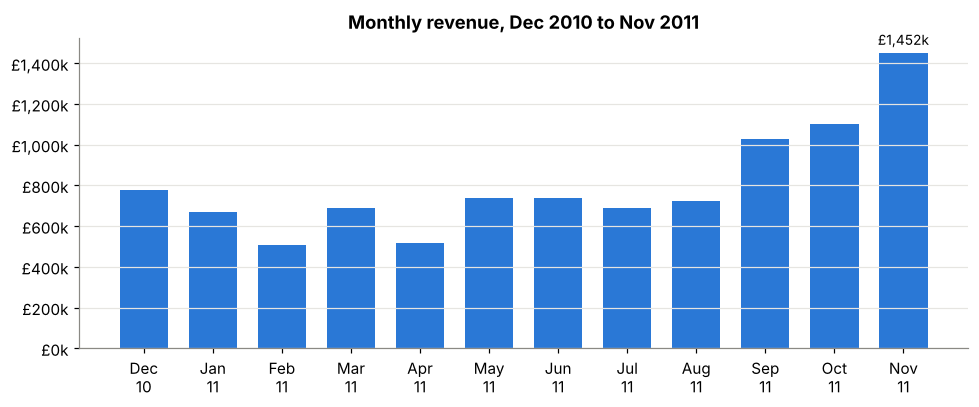

Sep-Nov 2011 share of 12-month revenue: 37.2%


In [11]:
monthly = FULL.groupby("Month").agg(revenue=("Revenue", "sum"), orders=("InvoiceNo", "nunique"))
monthly.index = monthly.index.astype(str)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(monthly.index, monthly["revenue"] / 1000, color=BLUE, width=0.7)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v:,.0f}k"))
ax.set_title("Monthly revenue, Dec 2010 to Nov 2011")
ax.set_xticks(range(len(monthly))); ax.set_xticklabels(pd.PeriodIndex(monthly.index, freq="M").strftime("%b\n%y"))
ax.grid(axis="x", visible=False)
peak = monthly["revenue"].idxmax()
ax.annotate(f"£{monthly.loc[peak, 'revenue']/1000:,.0f}k", (list(monthly.index).index(peak), monthly.loc[peak, "revenue"]/1000),
            ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
fig.tight_layout(); fig.savefig("images/monthly_revenue.png"); plt.show()

sep_nov_share = monthly.loc[["2011-09", "2011-10", "2011-11"], "revenue"].sum() / monthly["revenue"].sum()
print(f"Sep-Nov 2011 share of 12-month revenue: {sep_nov_share:.1%}")

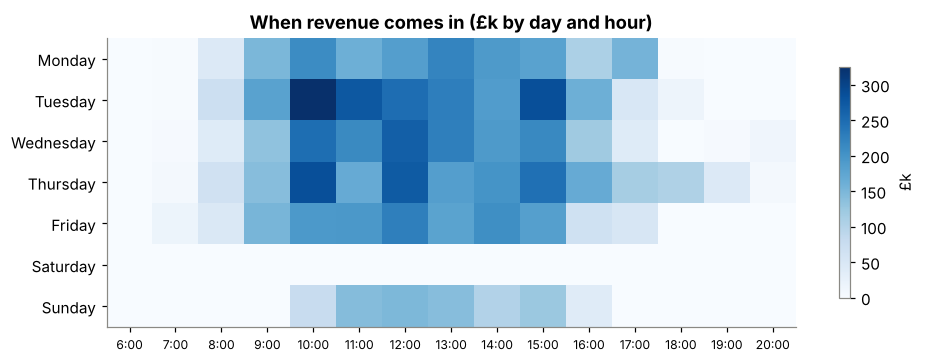

Saturday revenue: 0.0


In [12]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (FULL.assign(dow=FULL["InvoiceDate"].dt.day_name(), hour=FULL["InvoiceDate"].dt.hour)
            .pivot_table(index="dow", columns="hour", values="Revenue", aggfunc="sum")
            .reindex(dow_order).fillna(0))
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(heat.values / 1000, aspect="auto", cmap="Blues")
ax.set_yticks(range(7)); ax.set_yticklabels(dow_order)
ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels([f"{h}:00" for h in heat.columns], rotation=0, fontsize=8)
ax.grid(False); ax.set_title("When revenue comes in (£k by day and hour)")
fig.colorbar(im, ax=ax, shrink=0.8, label="£k"); fig.tight_layout(); fig.savefig("images/day_hour_heatmap.png"); plt.show()
print("Saturday revenue:", heat.loc["Saturday"].sum())

## 4. Export markets and product concentration

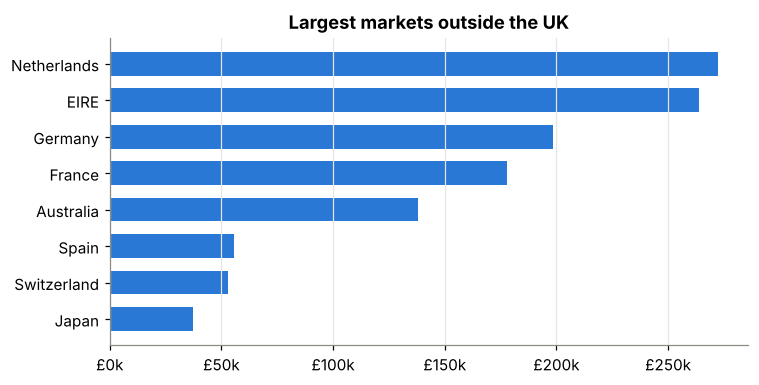

Country
Netherlands   272,161.32
EIRE          263,709.97
Germany       198,356.98
France        177,954.08
Australia     138,103.81
Spain          55,418.35
Switzerland    53,065.60
Japan          37,416.37
Name: Revenue, dtype: float64

In [13]:
by_country = FULL.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
top_export = by_country.drop("United Kingdom").head(8)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(top_export.index[::-1], top_export.values[::-1] / 1000, color=BLUE, height=0.65)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"£{v:,.0f}k"))
ax.set_title("Largest markets outside the UK"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("images/export_markets.png"); plt.show()
top_export

In [14]:
prod = FULL.groupby(["StockCode"]).agg(revenue=("Revenue", "sum"), description=("Description", "first")).sort_values("revenue", ascending=False)
prod["cum_share"] = prod["revenue"].cumsum() / prod["revenue"].sum()
n_80 = int((prod["cum_share"] < 0.8).sum() + 1)
pareto = {"products": len(prod), "products_for_80pct": n_80, "pct_products_for_80pct": round(100 * n_80 / len(prod), 1)}
print(pareto)
prod.head(10)[["description", "revenue"]]

{'products': 3904, 'products_for_80pct': 833, 'pct_products_for_80pct': 21.3}


,description,revenue
StockCode,,
22423,REGENCY CAKESTAND 3 TIER,"168,162.42"
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"102,236.34"
47566,PARTY BUNTING,"98,526.75"
85099B,JUMBO BAG RED RETROSPOT,"91,932.91"
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,448.21"
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"58,007.83"
23084,RABBIT NIGHT LIGHT,"57,241.57"
84879,ASSORTED COLOUR BIRD ORNAMENT,"56,764.88"
79321,CHILLI LIGHTS,"51,456.62"


## 5. Customer segmentation (RFM)

Each identified customer is scored 1 to 5 on **recency** (days since last order, measured from 1 December 2011), **frequency** (number of orders) and **monetary** value (total spend). Recency and frequency scores map to named segments using a standard RFM grid.

In [15]:
snapshot = pd.Timestamp("2011-12-01")
rfm = cust.groupby("CustomerID").agg(
    recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    frequency=("InvoiceNo", "nunique"),
    monetary=("Revenue", "sum"),
)
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

SEGMENTS = [
    (r"[1-2][1-2]", "Hibernating"), (r"[1-2][3-4]", "At risk"), (r"[1-2]5", "Can't lose them"),
    (r"3[1-2]", "About to sleep"), (r"33", "Need attention"), (r"[3-4][4-5]", "Loyal"),
    (r"41", "Promising"), (r"51", "New"), (r"[4-5][2-3]", "Potential loyalists"), (r"5[4-5]", "Champions"),
]
rf = rfm["R"].astype(str) + rfm["F"].astype(str)
rfm["segment"] = None
for pattern, name in SEGMENTS:
    rfm.loc[rf.str.fullmatch(pattern) & rfm["segment"].isna(), "segment"] = name

seg = (rfm.groupby("segment").agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
                                  median_recency_days=("recency", "median"), median_orders=("frequency", "median"))
          .sort_values("revenue", ascending=False))
seg["customer_share_pct"] = (100 * seg["customers"] / seg["customers"].sum()).round(1)
seg["revenue_share_pct"] = (100 * seg["revenue"] / seg["revenue"].sum()).round(1)
seg

,customers,revenue,median_recency_days,median_orders,customer_share_pct,revenue_share_pct
segment,,,,,,
Champions,605,"3,727,216.42",6.00,7.00,14.10,45.30
Loyal,815,"2,523,843.81",27.00,5.00,19.00,30.70
At risk,602,"625,327.41",140.50,3.00,14.00,7.60
Hibernating,1040,"487,046.14",223.00,1.00,24.20,5.90
Potential loyalists,480,"309,710.99",14.00,2.00,11.20,3.80
Can't lose them,74,"192,122.94",104.50,6.00,1.70,2.30
About to sleep,337,"153,993.02",51.00,1.00,7.80,1.90
Need attention,184,"152,846.89",49.00,2.00,4.30,1.90
Promising,99,"36,194.73",21.00,1.00,2.30,0.40


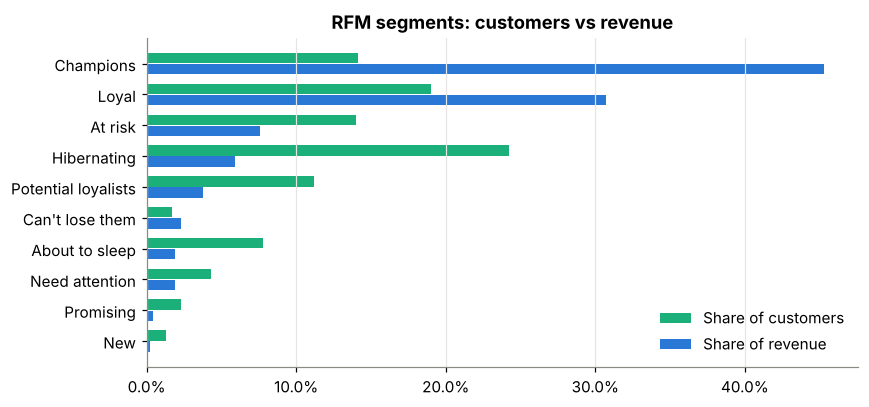

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(seg))
ax.barh(y + 0.18, seg["customer_share_pct"][::-1], height=0.34, color=AQUA, label="Share of customers")
ax.barh(y - 0.18, seg["revenue_share_pct"][::-1], height=0.34, color=BLUE, label="Share of revenue")
ax.set_yticks(y); ax.set_yticklabels(seg.index[::-1]); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("RFM segments: customers vs revenue"); ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig("images/rfm_segments.png"); plt.show()

## 6. Cohort retention

Customers are grouped by the month of their first order. Each cell is the share of that cohort who ordered again *n* months later. December 2010 is the first month in the data, so that cohort also contains customers who were already buying before the data starts.

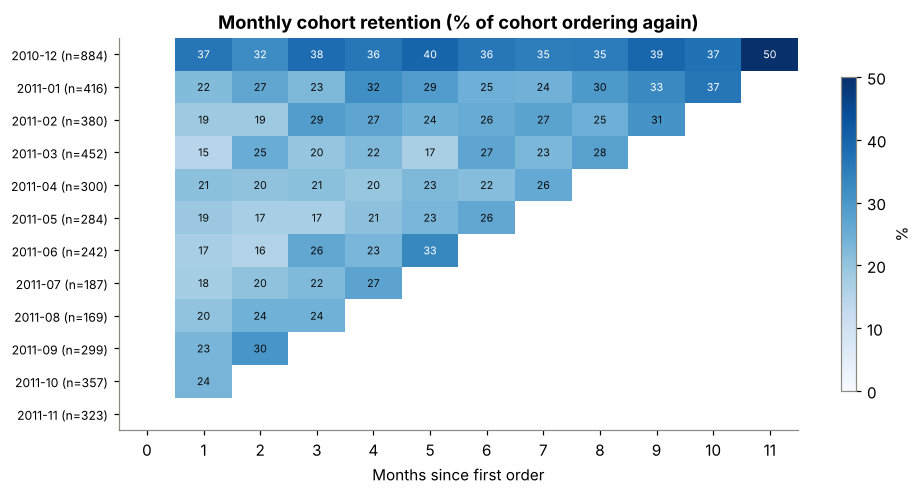

Dec 2010 cohort, month 1: 36.5%  |  later cohorts, month 1 average: 19.7%


In [17]:
c = cust[["CustomerID", "Month"]].drop_duplicates()
c["cohort"] = c.groupby("CustomerID")["Month"].transform("min")
c["offset"] = (c["Month"] - c["cohort"]).apply(lambda d: d.n)
counts = c.pivot_table(index="cohort", columns="offset", values="CustomerID", aggfunc="nunique")
retention = counts.div(counts[0], axis=0) * 100
retention.index = retention.index.astype(str)

fig, ax = plt.subplots(figsize=(9, 4.6))
shown = retention.copy(); shown[0] = np.nan  # month 0 is always 100%
im = ax.imshow(shown.values, cmap="Blues", vmin=0, vmax=50, aspect="auto")
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.values[i, j]
        if not np.isnan(v) and j > 0:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 32 else "#0b0b0b")
ax.set_yticks(range(len(retention))); ax.set_yticklabels([f"{p} (n={int(n)})" for p, n in zip(retention.index, counts[0])], fontsize=8)
ax.set_xticks(range(retention.shape[1])); ax.set_xlabel("Months since first order"); ax.grid(False)
ax.set_title("Monthly cohort retention (% of cohort ordering again)")
fig.colorbar(im, ax=ax, shrink=0.8, label="%"); fig.tight_layout(); fig.savefig("images/cohort_retention.png"); plt.show()

later = retention.loc[retention.index != "2010-12", 1]
print(f"Dec 2010 cohort, month 1: {retention.loc['2010-12', 1]:.1f}%  |  later cohorts, month 1 average: {later.mean():.1f}%")

## Findings

Figures cover the twelve full months, December 2010 to November 2011.

| Measure | Value |
|---|---|
| Revenue | £9.63m |
| Orders | 18,957 |
| Identified customers | 4,293 |
| Average / median order value | £508 / £302 |
| Revenue from the UK | 84.6% |
| Cancelled value as a share of sales | 7.2% |

1. **The business is heavily seasonal.** September to November brought in 37.2% of the year's revenue. November 2011 alone was £1.45m, about 2.9 times February. Stock, staffing and cash flow need planning around that peak.
2. **It trades on weekdays only.** There is no Saturday revenue at all, and most revenue arrives between 10:00 and 16:00, Tuesday to Thursday, which fits a business that sells to trade buyers.
3. **A few customers carry the business.** Champions are 14.1% of customers but 45.3% of revenue; with Loyal customers, a third of the base drives 76% of revenue.
4. **602 customers are at risk.** They ordered three times on median but not for about 140 days, and they spent £625k over the year. They are the obvious target for a win-back campaign.
5. **Export revenue sits with very few accounts.** The Netherlands (£272k) comes from 9 identified customers and Ireland (£264k) from 3. Losing one account would show up in the top line.
6. **A fifth of the range earns 80% of revenue.** 833 of 3,904 products account for 80% of sales.
7. **Repeat buying is strong but drops fast after the first order.** 63.9% of customers ordered more than once, yet on average only 19.7% of a new cohort ordered again the following month. Retention rises again in the autumn as customers return for the peak.
8. **14.6% of revenue has no customer ID.** Guest orders average £1,058, more than twice the identified average (£467), so they are worth investigating and capturing.

**Limitations.** One year of data from one retailer. The December 2010 cohort includes customers who were already buying before the data starts, which is why its retention is higher. Revenue is order value, not profit, because the data has no cost information.

In [18]:
summary = {
    "kpis": kpis,
    "cleaning_log": cleaning_log.to_dict(orient="records"),
    "monthly": [{"month": m, "revenue": round(r, 2), "orders": int(o)} for m, r, o in zip(monthly.index, monthly["revenue"], monthly["orders"])],
    "sep_nov_share_pct": round(100 * sep_nov_share, 1),
    "saturday_revenue": float(heat.loc["Saturday"].sum()),
    "day_hour": {"days": dow_order, "hours": [int(h) for h in heat.columns], "values": (heat.values / 1000).round(2).tolist()},
    "top_export": [{"country": k, "revenue": round(v, 2)} for k, v in top_export.items()],
    "uk_revenue": round(by_country["United Kingdom"], 2),
    "pareto": pareto,
    "top_products": [{"description": d, "revenue": round(r, 2)} for d, r in zip(prod.head(5)["description"], prod.head(5)["revenue"])],
    "rfm_segments": [{"segment": s, **{k: (round(float(v), 1) if isinstance(v, float) else int(v)) for k, v in row.items()}} for s, row in seg.iterrows()],
    "repeat": q("repeat_customer_rate").iloc[0].to_dict(),
    "aov_by_type": q("average_order_value_by_customer_type").to_dict(orient="records"),
    "cohort": {"cohorts": list(retention.index), "sizes": [int(n) for n in counts[0]],
               "values": [[None if np.isnan(v) else round(float(v), 1) for v in row] for row in retention.values]},
    "dec2010_month1": round(float(retention.loc["2010-12", 1]), 1),
    "later_month1_avg": round(float(later.mean()), 1),
}
json.dump(summary, open("results/summary.json", "w"), indent=1, default=str)
print("saved results/summary.json")

saved results/summary.json
